# SMS Spam Classification using SVM

Classify an English SMS as **Spam** or **Ham** using TF-IDF, six raw-message
features and a Linear SVM.

Dataset: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection),
Almeida & Hidalgo (2011), CC BY 4.0.

**Run locally:** open this notebook from the extracted project folder after
installing `requirements.txt`. **Run in Colab:** run the next cell and upload
the complete project ZIP when asked. A GPU is not required. Saved outputs below
are from a real full-grid run; running all cells recreates them.

## 1. Locate the project and prepare the environment

The shared preprocessing code lives in `sms_classifier.py`. Keeping the
transformer in an importable module makes saved-model loading work outside this notebook.
Colab installs the project's dependencies automatically. Local users install
them with the commands in the README before opening Jupyter.

In [1]:
from pathlib import Path
import os
import sys
import zipfile

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

project_candidates = [Path.cwd(), Path.cwd() / "sms-spam-svm"]
ROOT = next((p for p in project_candidates if (p / "sms_classifier.py").is_file()), None)

if ROOT is None and IN_COLAB:
    print("Upload SMS_Spam_SVM_GitHub_Ready.zip (the complete project ZIP).")
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload exactly one project ZIP file.")
    destination = Path.cwd() / "sms_project_files"
    destination.mkdir(exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError("Unsafe ZIP path.")
        archive.extractall(destination)
    modules = list(destination.rglob("sms_classifier.py"))
    if len(modules) != 1:
        raise ValueError("The ZIP must contain exactly one sms_classifier.py.")
    ROOT = modules[0].parent

if ROOT is None:
    raise FileNotFoundError("Open this notebook from the extracted sms-spam-svm folder.")
ROOT = ROOT.resolve()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if IN_COLAB:
    get_ipython().run_line_magic("pip", "install -q -r requirements.txt")
print("Project files located. Colab:", IN_COLAB)

Project files located. Colab: False


## 2. Imports and configuration

NLTK downloads English stopwords and WordNet if missing. The full grid contains
24 configurations and five folds (120 fits). For a shorter demonstration, change
`QUICK_MODE` to `True`. One worker is used to limit memory use.

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, f1_score
from IPython.display import display, Image

from sms_classifier import (
    setup_nltk, load_dataset, clean_text, extract_spam_features,
    SMSFeatureBuilder, build_pipeline, parameter_grid, top_features, predict_sms,
)
from train import save_evaluation

QUICK_MODE = False
RANDOM_STATE = 42
N_JOBS = 1
setup_nltk()
sns.set_theme(style="whitegrid")
print("Dependencies ready. Quick mode:", QUICK_MODE)

Dependencies ready. Quick mode: False


## 3. Load and validate the dataset

This UCI CSV contains 5,574 rows, rather than the 5,572 reported for some Kaggle
versions. The loader trims surrounding whitespace, rejects conflicting labels
for identical messages and removes repeated messages **before** splitting.

In [3]:
df = load_dataset(ROOT / "data" / "spam.csv")
print(json.dumps(df.attrs["dataset_summary"], indent=2))
display(df.head())

{
  "raw_rows": 5574,
  "invalid_or_empty_rows_removed": 0,
  "duplicate_messages_removed": 414,
  "usable_rows": 5160,
  "class_counts": {
    "ham": 4518,
    "spam": 642
  }
}


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 4. Hold out the test set

Stratification preserves the class proportions approximately. Training folds
and EDA use the training set; the test set is reserved for final evaluation.
The target is 0 for ham and 1 for spam.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["target"], test_size=0.20,
    random_state=RANDOM_STATE, stratify=df["target"],
)
print("Training messages:", len(X_train))
print("Test messages:", len(X_test))
assert set(X_train).isdisjoint(set(X_test)), "A repeated message crossed the split!"
training_df = pd.DataFrame({"message": X_train, "label": y_train.map({0: "ham", 1: "spam"})})

Training messages: 4128
Test messages: 1032


## 5. Exploratory data analysis

Compare the class counts and lengths of **training** messages. Most messages
are ham, so a high accuracy alone can hide poor spam detection.

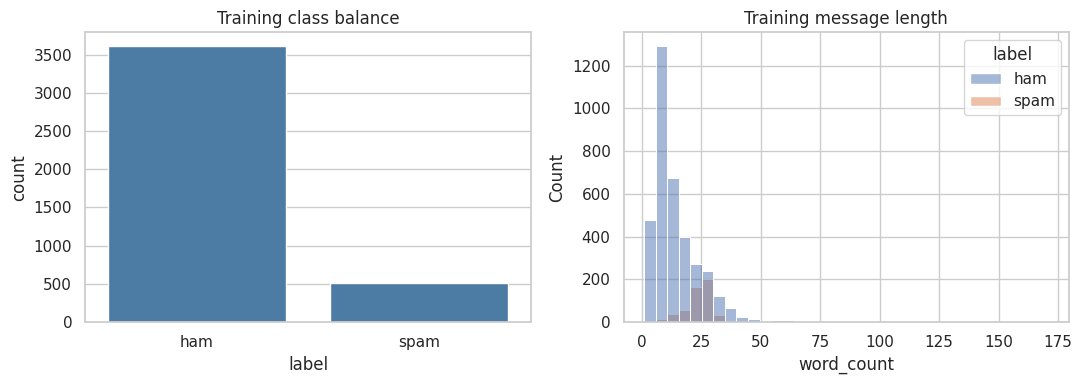

In [5]:
training_df["word_count"] = training_df["message"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=training_df, x="label", order=["ham", "spam"], ax=axes[0], color="#3e7cb1")
axes[0].set_title("Training class balance")
sns.histplot(data=training_df, x="word_count", hue="label", bins=35, ax=axes[1])
axes[1].set_title("Training message length")
fig.tight_layout()
fig.savefig(ROOT / "results" / "eda.png", dpi=170)
plt.show()

## 6. Word clouds

These pictures summarize common training words. They are exploratory visuals;
the classifier itself learns from TF-IDF and numeric features.

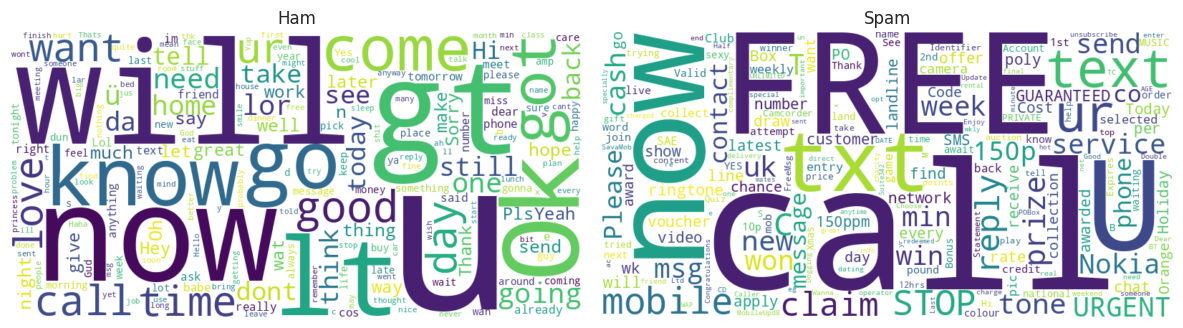

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label in zip(axes, ["ham", "spam"]):
    text = " ".join(training_df.loc[training_df.label == label, "message"])
    cloud = WordCloud(width=800, height=400, background_color="white",
                      random_state=RANDOM_STATE, collocations=False).generate(text)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(label.capitalize())
    ax.axis("off")
fig.tight_layout()
fig.savefig(ROOT / "results" / "wordclouds.png", dpi=170)
plt.show()

## 7. Cleaning and raw-message features

Cleaning removes digits, case and punctuation from text. We preserve these
signals in six numeric features computed from the original SMS. This example
shows both representations. WordNet uses noun lemmatization by default.

In [7]:
example = "FREE £500 prize!!! Visit https://example.com NOW!"
print("Original:", example)
print("Cleaned:", clean_text(example))
display(pd.DataFrame([extract_spam_features(example)]))
feature_example = SMSFeatureBuilder().fit_transform(X_train.head())
display(feature_example)

Original: FREE £500 prize!!! Visit https://example.com NOW!
Cleaned: free £ prize visit


,exclamation_count,digit_count,uppercase_ratio,message_length,has_url,has_money_or_bait_word
0,4,3,0.25,49,1,1


,clean_message,exclamation_count,digit_count,uppercase_ratio,message_length,has_url,has_money_or_bait_word
0,got arrested possession shit lt time gt pm,0,0,0.125000,67,0,0
1,going sleep tired travel,0,0,0.064516,42,0,0
2,chance win free bluetooth headset simply reply...,0,0,0.200000,81,0,1
3,cool text head,0,0,0.041667,31,0,0
4,ill call u mrw ninish address icky american fr...,0,2,0.038462,103,0,0


## 8. Build the complete pipeline

`SMSFeatureBuilder` produces cleaned text and numeric signals. `ColumnTransformer`
combines TF-IDF with numeric scaling. `LinearSVC` learns the class boundary.
Putting learned transformations inside the pipeline avoids learning vocabulary
or scaling parameters from validation folds.

In [8]:
pipeline = build_pipeline()
display(pipeline)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('raw_features', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tfidf', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different t

## 9. Hyperparameter tuning on training folds

`C` controls the strength of SVM regularization; smaller C means stronger
regularization. The full search also tries unigrams vs. bigrams, vocabulary
limits and class weighting. The scoring target is **spam F1**, not accuracy.
The best CV score is a model-selection score and can be optimistic after selection.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    pipeline, parameter_grid(QUICK_MODE), scoring="f1", cv=cv,
    n_jobs=N_JOBS, refit=True, error_score="raise", verbose=1,
)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best training-fold selection F1:", round(grid.best_score_, 4))
cv_table = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
display(cv_table[["rank_test_score", "mean_test_score", "std_test_score", "params"]].head(8))
cv_table.to_csv(ROOT / "results" / "cv_results.csv", index=False)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'features__tfidf__max_features': 5000, 'features__tfidf__ngram_range': (1, 2), 'svm__C': 1.0, 'svm__class_weight': 'balanced'}
Best training-fold selection F1: 0.9426


,rank_test_score,mean_test_score,std_test_score,params
21,1,0.942648,0.021300,"{'features__tfidf__max_features': 5000, 'featu..."
22,2,0.942208,0.022300,"{'features__tfidf__max_features': 5000, 'featu..."
10,3,0.942169,0.023215,"{'features__tfidf__max_features': 3000, 'featu..."
3,4,0.941751,0.022916,"{'features__tfidf__max_features': 3000, 'featu..."
15,5,0.941537,0.025773,"{'features__tfidf__max_features': 5000, 'featu..."
9,6,0.941122,0.020053,"{'features__tfidf__max_features': 3000, 'featu..."
16,7,0.938973,0.022584,"{'features__tfidf__max_features': 5000, 'featu..."
17,8,0.938180,0.023796,"{'features__tfidf__max_features': 5000, 'featu..."


## 10. Final held-out evaluation

Precision measures how often a spam prediction is correct. Recall measures how
much of the actual spam is detected. F1 is their harmonic mean. Average precision
summarizes the precision–recall ranking curve; it is not identical to trapezoidal PR-AUC.

In [10]:
test_prediction = best_model.predict(X_test)
print(classification_report(y_test, test_prediction, target_names=["ham", "spam"], digits=4))
metrics = save_evaluation(best_model, X_test, y_test, ROOT / "results")
display(pd.DataFrame({"Metric": ["Accuracy", "Spam precision", "Spam recall", "Spam F1",
                                 "Average precision", "Always-ham baseline accuracy"],
                      "Value": [metrics[key] for key in ["accuracy", "spam_precision", "spam_recall",
                                                          "spam_f1", "average_precision",
                                                          "majority_baseline_accuracy"]]}))

              precision    recall  f1-score   support

         ham     0.9945    0.9978    0.9961       904
        spam     0.9840    0.9609    0.9723       128

    accuracy                         0.9932      1032
   macro avg     0.9892    0.9794    0.9842      1032
weighted avg     0.9932    0.9932    0.9932      1032



,Metric,Value
0,Accuracy,0.993217
1,Spam precision,0.984000
2,Spam recall,0.960938
3,Spam F1,0.972332
4,Average precision,0.989928
5,Always-ham baseline accuracy,0.875969


## 11. Confusion matrix and precision–recall curve

The matrix shows actual labels on rows and predictions on columns. A false
positive is ham predicted as spam; a false negative is spam predicted as ham.
The PR curve uses SVM `decision_function` scores. Scores are not probabilities,
and calibration is **not necessary** to draw a PR curve.

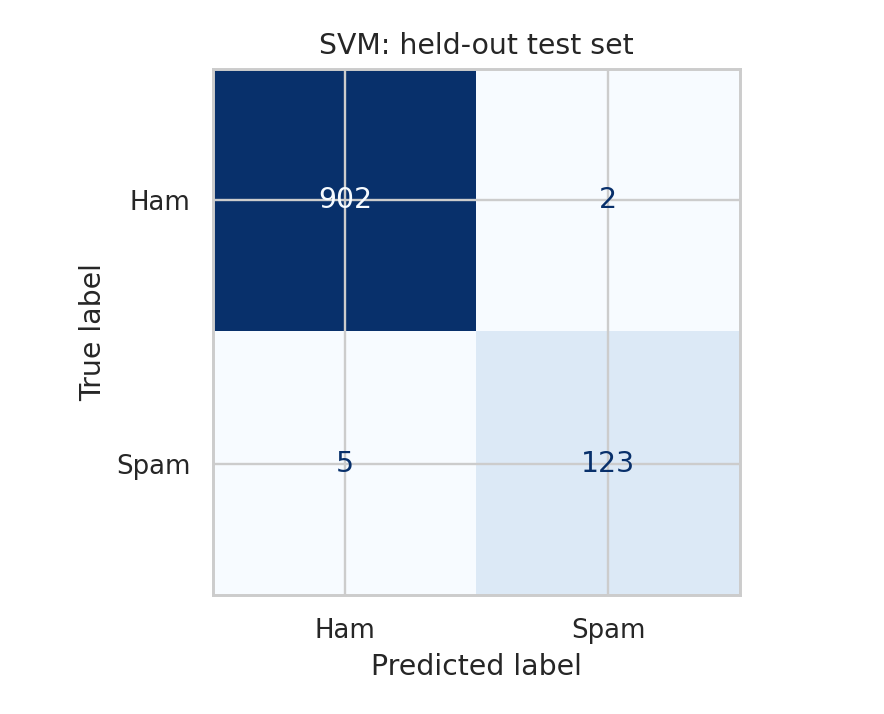

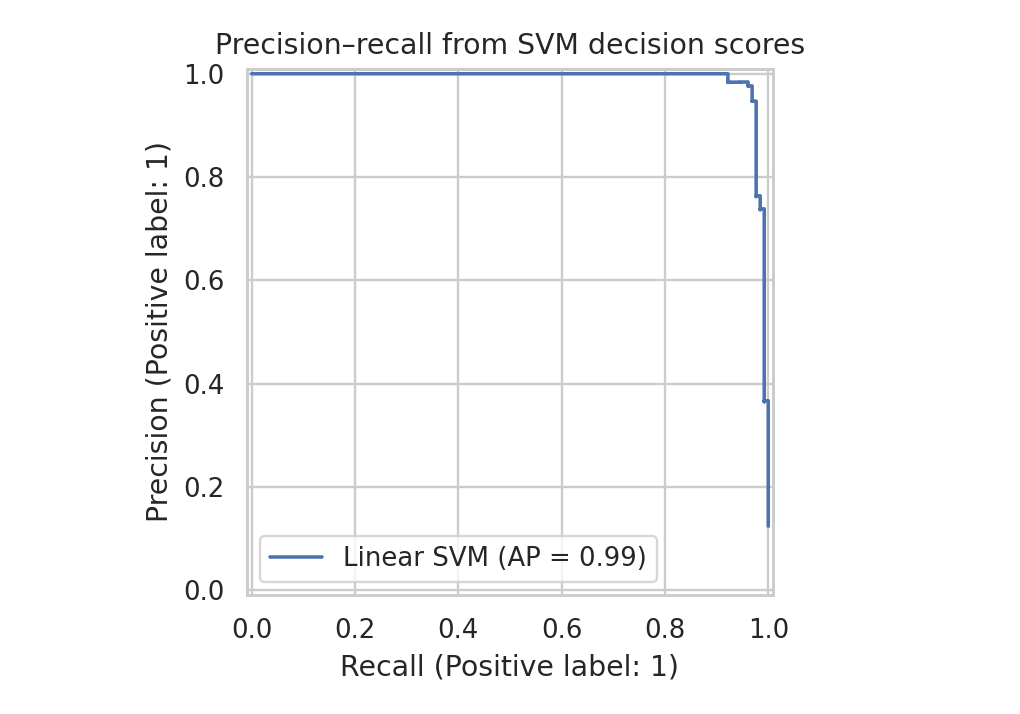

In [11]:
display(Image(filename=str(ROOT / "results" / "confusion_matrix.png")))
display(Image(filename=str(ROOT / "results" / "precision_recall_curve.png")))

## 12. Inspect influential features

Positive coefficients push the decision toward spam; negative coefficients
push it toward ham. These are model associations, not proof that a word causes
spam. Numeric features are measured after scaling, so interpret weights with care.

Top spam-indicative features
Top ham-indicative features


,feature,weight
0,tfidf__ringtone,1.657266
1,tfidf__rgds,1.591348
2,tfidf__tone,1.449237
3,tfidf__mobile,1.443552
4,tfidf__ltd,1.346352
5,tfidf__girl waiting,1.338789
6,tfidf__service,1.305419
7,tfidf__arsenal,1.226248
8,tfidf__new,1.196907
9,tfidf__uk,1.196107


,feature,weight
0,tfidf__gt,-1.046866
1,tfidf__lt,-1.045282
2,tfidf__lt gt,-1.004650
3,tfidf__ubi,-0.978297
4,tfidf__got,-0.914039
5,tfidf__hey,-0.815607
6,tfidf__bedrm,-0.801111
7,tfidf__ard,-0.795475
8,tfidf__ah,-0.758286
9,tfidf__park,-0.636153


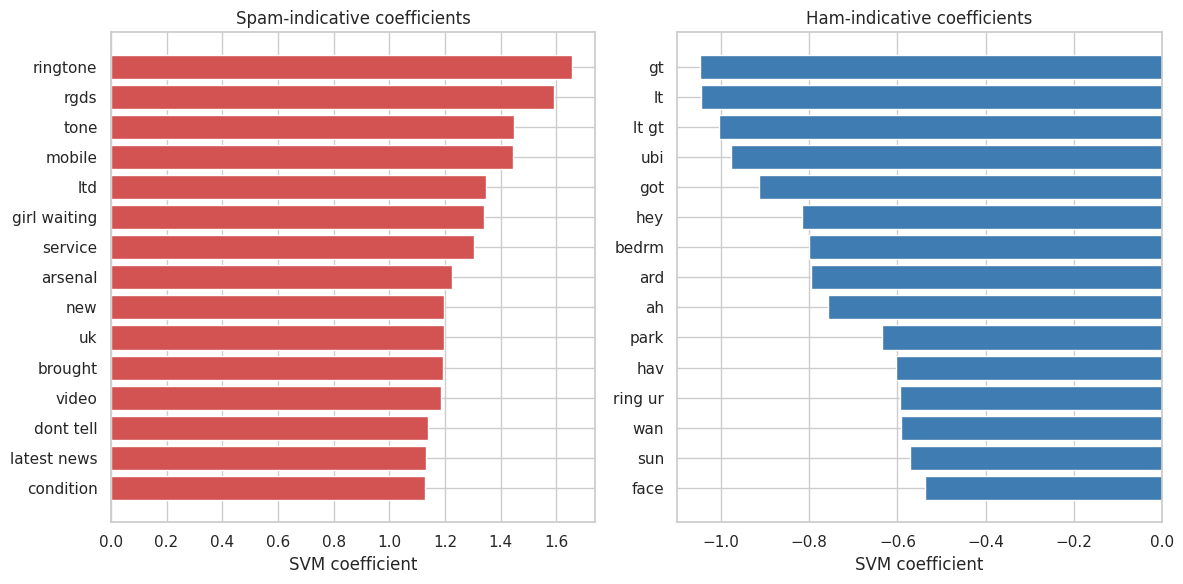

In [12]:
spam_features, ham_features = top_features(best_model)
print("Top spam-indicative features")
display(spam_features)
print("Top ham-indicative features")
display(ham_features)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, frame, title, color in [
    (axes[0], spam_features.iloc[::-1], "Spam-indicative coefficients", "#d35252"),
    (axes[1], ham_features.iloc[::-1], "Ham-indicative coefficients", "#3e7cb1"),
]:
    ax.barh(frame.feature.str.replace("tfidf__", "", regex=False), frame.weight, color=color)
    ax.set_title(title)
    ax.set_xlabel("SVM coefficient")
fig.tight_layout()
fig.savefig(ROOT / "results" / "feature_weights.png", dpi=170)
plt.show()

## 13. Error analysis

Inspect the original SMS text for incorrect predictions. Keep these examples
for discussion; repeatedly changing parameters based on test errors would make
the held-out test set less reliable as an independent evaluation.

In [13]:
errors = pd.read_csv(ROOT / "results" / "misclassified_messages.csv")
print("Misclassified:", len(errors), "out of", len(X_test))
with pd.option_context("display.max_colwidth", 140):
    display(errors.head(10))

Misclassified: 7 out of 1032


,message,true_label,predicted_label,decision_score
0,"A Boy loved a gal. He propsd bt she didnt mind. He gv lv lttrs, Bt her frnds threw thm. Again d boy decided 2 aproach d gal , dt time a ...",ham,spam,0.377957
1,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,spam,ham,-0.189974
2,thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the potential for abuse???,spam,ham,-0.658504
3,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?,spam,ham,-1.040649
4,Welcome! Please reply with your AGE and GENDER to begin. e.g 24M,spam,ham,-0.327855
5,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties...",spam,ham,-0.695378
6,Your bill at 3 is £33.65 so thats not bad!,ham,spam,0.315593


## 14. Save and reload the complete model

The model accepts raw messages, so preprocessing is retained. A separate Python
process can load it as long as `sms_classifier.py`, NLTK resources and compatible
dependencies are available. Only load joblib artifacts from trusted sources.

In [14]:
import hashlib
import platform
import sklearn
import nltk

metrics.update({
    "dataset": df.attrs["dataset_summary"],
    "dataset_sha256": hashlib.sha256((ROOT / "data" / "spam.csv").read_bytes()).hexdigest(),
    "training_rows": len(X_train), "test_rows": len(X_test),
    "random_state": RANDOM_STATE, "cv_folds": 5,
    "search_mode": "quick" if QUICK_MODE else "full",
    "best_parameters": grid.best_params_,
    "best_training_cv_f1": float(grid.best_score_),
    "cv_note": "Selection score from training folds; not an unbiased post-selection estimate.",
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "nltk": nltk.__version__},
})
(ROOT / "results" / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(best_model, ROOT / "models" / "sms_spam_model.joblib")
loaded_model = joblib.load(ROOT / "models" / "sms_spam_model.joblib")
assert np.array_equal(best_model.predict(X_test), loaded_model.predict(X_test))
print("Saved models/sms_spam_model.joblib. Reloaded predictions match.")

Saved models/sms_spam_model.joblib. Reloaded predictions match.


## 15. Predict new messages

Change these strings to try your own examples. The model is trained on an old
English SMS dataset and has not been validated for Bangla or modern scams.

The original iPhone-prize example is a challenging spam message that the included
model predicts as ham (a false negative). It is retained to show the limitation.

In [15]:
new_messages = [
    "Congratulations! You won a free prize. Call 12345 now!",
    "Congratulations! You have won a free iPhone. Click here now.",
    "Hi, are we meeting tomorrow at 3 PM?",
]
for text in new_messages:
    print(f"{predict_sms(loaded_model, text):4} | {text}")

Spam | Congratulations! You won a free prize. Call 12345 now!
Ham  | Congratulations! You have won a free iPhone. Click here now.
Ham  | Hi, are we meeting tomorrow at 3 PM?


## 16. Optional calibrated probabilities

If a future application needs estimated probabilities, enable this section.
The calibration folds use **training messages only**, and the fitted calibrated
estimator is a separate model. Probability calibration adds computation and
does not guarantee reliability on a different real-world distribution. This
section is disabled by default and does not affect the reported SVM results.

In [16]:
RUN_CALIBRATION = False
if RUN_CALIBRATION:
    from sklearn.base import clone
    calibrated_model = CalibratedClassifierCV(
        clone(best_model), method="sigmoid",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    )
    calibrated_model.fit(X_train, y_train)
    probabilities = calibrated_model.predict_proba(new_messages)[:, 1]
    display(pd.DataFrame({"message": new_messages, "estimated_spam_probability": probabilities}))
    joblib.dump(calibrated_model, ROOT / "models" / "sms_spam_calibrated.joblib")
else:
    print("Optional probability calibration skipped.")

Optional probability calibration skipped.


## 17. Optional: download generated files from Colab

Set `DOWNLOAD_RESULTS = True` and rerun this cell to download the model, shared
Python module and result files before your Colab session ends.

In [17]:
DOWNLOAD_RESULTS = False
if IN_COLAB and DOWNLOAD_RESULTS:
    output_zip = ROOT / "generated_sms_results.zip"
    with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as archive:
        for folder in [ROOT / "models", ROOT / "results"]:
            for path in folder.rglob("*"):
                if path.is_file():
                    archive.write(path, path.relative_to(ROOT))
        for name in ["sms_classifier.py", "predict.py", "requirements.txt"]:
            archive.write(ROOT / name, name)
    files.download(str(output_zip))
else:
    print("Files are available in the project's models/ and results/ folders.")

Files are available in the project's models/ and results/ folders.


## Conclusion

This project combines cleaned text with raw spam signals and evaluates a tuned
SVM on a separate test set. Use the printed metrics as the measured result for
this dataset and split. Next experiments could compare character n-grams,
ComplementNB or LogisticRegression without changing the final test protocol.